# Extension — Random Forest & Gradient Boosting vs Logistic Regression

**Why?** Logistic regression draws one smooth, straight-line-style boundary (AUC ≈ 0.79). Tree-based models can learn *interactions* (e.g. "long lead time AND non-refundable AND city hotel") and non-linear effects automatically, so they should rank risky bookings better.

1. Setup (same features and same split as `04_classification.ipynb` — a fair comparison)  
2. Train all models  
3. Compare (threshold 0.5 and threshold-free AUC)  
4. Tune the threshold properly (on a validation set, not the test set)  
5. What drives the best model?  
6. Update the Power BI export

## 1. Setup

In [1]:
import os, time
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

os.makedirs("../outputs/figures", exist_ok=True)
path = "../data/processed/hotel_bookings_cleaned.csv"
if not os.path.exists(path): path = "hotel_bookings_cleaned.csv"
df = pd.read_csv(path)

# Same leakage-free feature list as notebook 04 (ReservationStatus / ReservationStatusDate excluded)
features = ["Hotel","LeadTime","ArrivalDateMonth","ArrivalDateYear","ArrivalDateWeekNumber",
            "StaysInWeekendNights","StaysInWeekNights","Adults","Children","Babies","Meal",
            "MarketSegment","DistributionChannel","IsRepeatedGuest","PreviousCancellations",
            "PreviousBookingsNotCanceled","ReservedRoomType","DepositType","DaysInWaitingList",
            "CustomerType","ADR","RequiredCarParkingSpaces","TotalOfSpecialRequests","BookingChanges"]
features_c = features + ["Country"]          # Country = 178 levels; trees handle this far better than logistic regression
y = df["IsCanceled"]

def is_cat(c): return not pd.api.types.is_numeric_dtype(df[c])
# Same random_state as notebook 04 -> identical train/test rows
X_train, X_test, y_train, y_test = train_test_split(df[features_c], y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(69916, 25) (17480, 25)


## 2. Build and train the models

- **Logistic regression** — one-hot encoded + scaled (as before).
- **Random forest** — many decision trees, each trained on a random sample of rows/features; they vote. Averaging reduces overfitting. Trees don't need scaling, so categories are simply turned into integer codes.
- **Gradient boosting** (`HistGradientBoostingClassifier`) — trees are built *one after another*, each correcting the previous trees' mistakes. It is told which columns are categorical, so it treats them properly.

In [2]:
def ordinal_pre(cols):
    cat = [c for c in cols if is_cat(c)]
    pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat)],
                            remainder="passthrough")
    cat_mask = [True]*len(cat) + [False]*(len(cols)-len(cat))   # categorical columns come first after the transformer
    return pre, cat_mask

def logit_pipe(cols):
    cat = [c for c in cols if is_cat(c)]; num = [c for c in cols if c not in cat]
    pre = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(max_iter=2000))])

def rf_pipe(cols):
    pre, _ = ordinal_pre(cols)
    return Pipeline([("prep", pre), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42))])

def gb_pipe(cols):
    pre, mask = ordinal_pre(cols)
    return Pipeline([("prep", pre), ("clf", HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.1, categorical_features=mask, random_state=42))])

models = {
    "Logistic Regression":          (logit_pipe(features),   features),
    "Random Forest":                (rf_pipe(features),      features),
    "Gradient Boosting":            (gb_pipe(features),      features),
    "Logistic Reg. + Country":      (logit_pipe(features_c), features_c),
    "Random Forest + Country":      (rf_pipe(features_c),    features_c),
    "Gradient Boosting + Country":  (gb_pipe(features_c),    features_c),
}
fitted = {}
for name, (pipe, cols) in models.items():
    t = time.time(); pipe.fit(X_train[cols], y_train); fitted[name] = (pipe, cols)
    print(f"{name:30s} trained in {time.time()-t:5.1f}s")

Logistic Regression            trained in   3.8s
Random Forest                  trained in  10.0s
Gradient Boosting              trained in   7.5s
Logistic Reg. + Country        trained in   3.3s
Random Forest + Country        trained in  12.0s
Gradient Boosting + Country    trained in   6.8s


Random Forest                  trained in  20.4s


Gradient Boosting              trained in   2.7s


Logistic Reg. + Country        trained in   1.7s


Random Forest + Country        trained in  25.3s


Gradient Boosting + Country    trained in   3.1s


## 3. Compare on the same test set

In [3]:
rows = []
for name, (pipe, cols) in fitted.items():
    p = pipe.predict_proba(X_test[cols])[:,1]; pred = (p >= 0.5).astype(int)
    rows.append({"Model":name, "Accuracy":accuracy_score(y_test,pred), "Precision":precision_score(y_test,pred),
                 "Recall":recall_score(y_test,pred), "F1":f1_score(y_test,pred), "ROC-AUC":roc_auc_score(y_test,p)})
comp = pd.DataFrame(rows)
print(comp.round(3).to_string(index=False))

                      Model  Accuracy  Precision  Recall    F1  ROC-AUC
        Logistic Regression     0.784      0.690   0.388 0.497    0.794
              Random Forest     0.815      0.740   0.505 0.601    0.857
          Gradient Boosting     0.811      0.723   0.507 0.596    0.849
    Logistic Reg. + Country     0.791      0.675   0.466 0.551    0.834
    Random Forest + Country     0.838      0.753   0.613 0.676    0.899
Gradient Boosting + Country     0.837      0.736   0.632 0.680    0.900


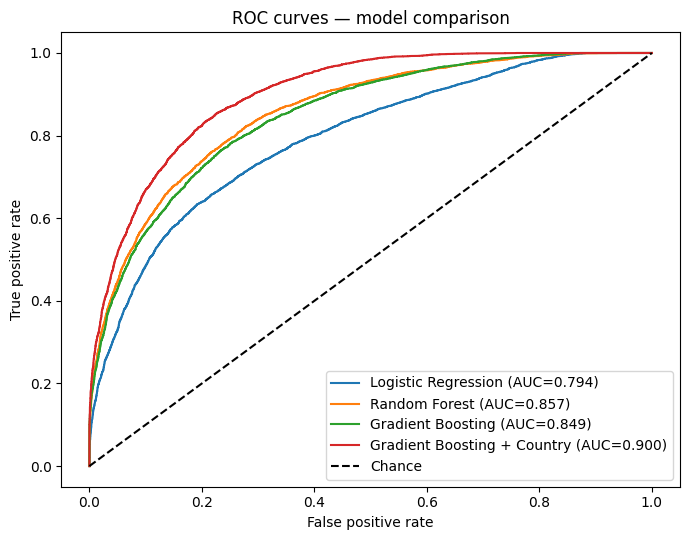

In [4]:
fig, ax = plt.subplots(figsize=(7,5.5))
for name in ["Logistic Regression","Random Forest","Gradient Boosting","Gradient Boosting + Country"]:
    pipe, cols = fitted[name]
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test[cols])[:,1])
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, pipe.predict_proba(X_test[cols])[:,1]):.3f})")
ax.plot([0,1],[0,1],"k--",label="Chance"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves — model comparison"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("../outputs/figures/model_roc_comparison.png", dpi=120); plt.show()

**Reading it.** AUC is threshold-free, so it is the fairest comparison of how well each model *ranks* risky bookings. The tree models beat logistic regression clearly, and adding `Country` helps a lot for every model — most for the tree models.

The 0.5-threshold precision/recall numbers are still affected by the 27.5% class imbalance, so next we tune the threshold the right way.

## 4. Tune the threshold properly

In notebook 04 we looked at thresholds directly on the test set. Choosing a threshold *on the test set* and then reporting test scores is slightly optimistic. Better: carve a **validation set** out of the training data, pick the threshold there, and only then score once on the untouched test set.

In [5]:
best_name = "Gradient Boosting + Country"
cols = features_c
X_tr, X_val, y_tr, y_val = train_test_split(X_train[cols], y_train, test_size=0.25, stratify=y_train, random_state=1)

val_model = gb_pipe(cols).fit(X_tr, y_tr)
p_val = val_model.predict_proba(X_val)[:,1]
grid = np.arange(0.10, 0.80, 0.01)
f1s = [f1_score(y_val, (p_val >= t).astype(int)) for t in grid]
best_t = float(grid[int(np.argmax(f1s))])
print(f"Best threshold on validation set: {best_t:.2f}  (F1 = {max(f1s):.3f})")

final_model, _ = fitted[best_name]
p_test = final_model.predict_proba(X_test[cols])[:,1]
for t in [0.5, best_t]:
    pr = (p_test >= t).astype(int)
    print(f"threshold {t:.2f} -> Precision {precision_score(y_test,pr):.3f} | Recall {recall_score(y_test,pr):.3f} | "
          f"F1 {f1_score(y_test,pr):.3f} | Accuracy {accuracy_score(y_test,pr):.3f}")

Best threshold on validation set: 0.34  (F1 = 0.717)
threshold 0.50 -> Precision 0.736 | Recall 0.632 | F1 0.680 | Accuracy 0.837
threshold 0.34 -> Precision 0.639 | Recall 0.781 | F1 0.703 | Accuracy 0.819


threshold 0.50 -> Precision 0.736 | Recall 0.632 | F1 0.680 | Accuracy 0.837
threshold 0.34 -> Precision 0.639 | Recall 0.781 | F1 0.703 | Accuracy 0.819


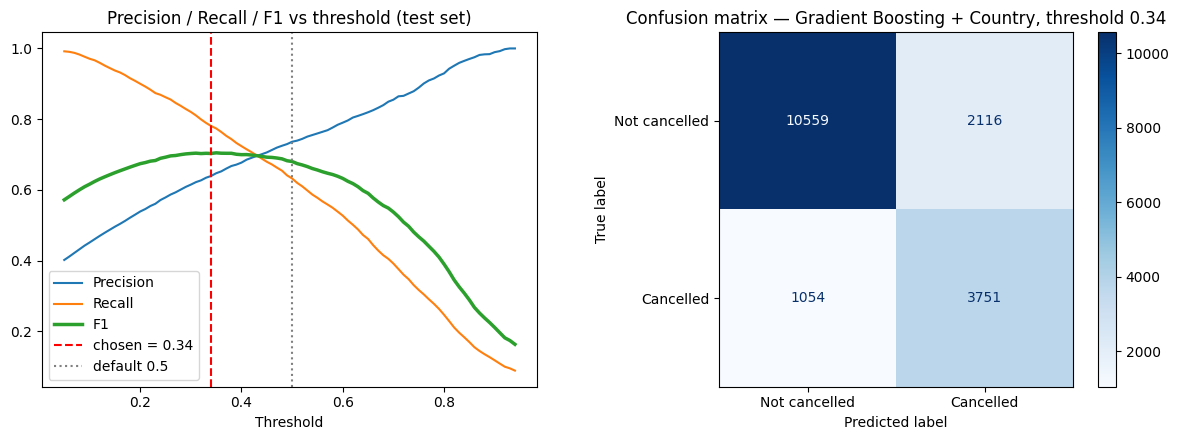

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ts = np.arange(0.05, 0.95, 0.01)
ax[0].plot(ts, [precision_score(y_test,(p_test>=t).astype(int)) for t in ts], label="Precision")
ax[0].plot(ts, [recall_score(y_test,(p_test>=t).astype(int)) for t in ts], label="Recall")
ax[0].plot(ts, [f1_score(y_test,(p_test>=t).astype(int)) for t in ts], label="F1", lw=2.5)
ax[0].axvline(best_t, color="red", ls="--", label=f"chosen = {best_t:.2f}"); ax[0].axvline(0.5, color="grey", ls=":", label="default 0.5")
ax[0].set_xlabel("Threshold"); ax[0].set_title("Precision / Recall / F1 vs threshold (test set)"); ax[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test, (p_test>=best_t).astype(int), display_labels=["Not cancelled","Cancelled"],
                                        cmap="Blues", ax=ax[1], values_format="d")
ax[1].set_title(f"Confusion matrix — {best_name}, threshold {best_t:.2f}")
plt.tight_layout(); plt.savefig("../outputs/figures/gb_threshold_confusion.png", dpi=120); plt.show()

The threshold is a **business choice** — a higher threshold means fewer false alarms but more missed cancellations. The validation-picked value balances the two (best F1).

## 5. What drives the best model?

Permutation importance: shuffle one column at a time on the test set and see how much AUC drops. A bigger drop = the model relies on that column more. (Importance ≠ direction; for direction see the logistic odds ratios in notebook 04.)

Country                        0.1125
MarketSegment                  0.0919
LeadTime                       0.0797
RequiredCarParkingSpaces       0.0756
TotalOfSpecialRequests         0.0499
ArrivalDateYear                0.0361
ADR                            0.0307
CustomerType                   0.0231
PreviousCancellations          0.0129
PreviousBookingsNotCanceled    0.0117
BookingChanges                 0.0093
ArrivalDateMonth               0.0075
dtype: float64


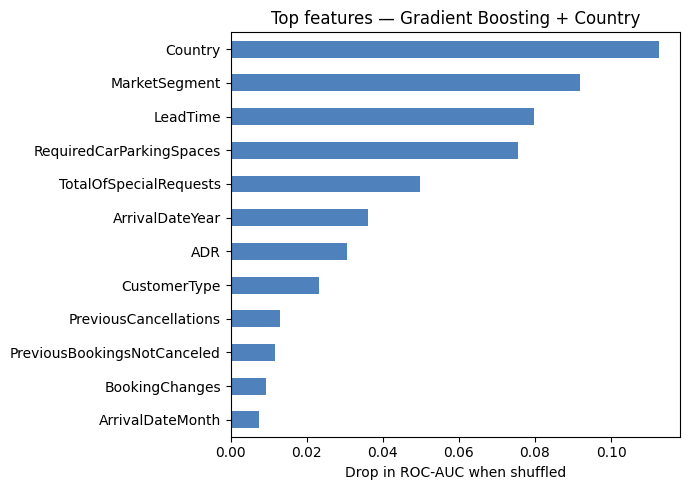

In [7]:
pi = permutation_importance(final_model, X_test[cols], y_test, scoring="roc_auc",
                            n_repeats=3, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)
print(imp.head(12).round(4))
imp.head(12).sort_values().plot.barh(color="#4f81bd", figsize=(7,5))
plt.xlabel("Drop in ROC-AUC when shuffled"); plt.title("Top features — Gradient Boosting + Country")
plt.tight_layout(); plt.savefig("../outputs/figures/gb_feature_importance.png", dpi=120); plt.show()

## 6. Update the Power BI export

5-fold out-of-fold probabilities from both the logistic model and the gradient boosting model, so every booking is scored by a model that did not train on it. `RiskBand` and `Outcome` now come from the better model at the tuned threshold.

In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_lr = cross_val_predict(logit_pipe(features),  df[features],   y, cv=skf, method="predict_proba")[:,1]
oof_gb = cross_val_predict(gb_pipe(features_c),   df[features_c],  y, cv=skf, method="predict_proba")[:,1]
print("Out-of-fold ROC-AUC  LR:", round(roc_auc_score(y, oof_lr),3), "| GB+Country:", round(roc_auc_score(y, oof_gb),3))

out = df.copy()
out["PredCancelProb_LR"] = oof_lr.round(4)
out["PredCancelProb"]    = oof_gb.round(4)                      # best model
out["PredCancelled"]     = (oof_gb >= best_t).astype(int)
out["RiskBand"] = pd.cut(oof_gb, [-0.01, 0.2, 0.5, 1.0], labels=["Low","Medium","High"])
out["Outcome"] = np.select(
    [(out.IsCanceled==1)&(out.PredCancelled==1), (out.IsCanceled==0)&(out.PredCancelled==0), (out.IsCanceled==0)&(out.PredCancelled==1)],
    ["True Positive","True Negative","False Positive"], default="False Negative")
print(out.groupby("RiskBand", observed=True)["IsCanceled"].agg(["count","mean"]).round(3))
out.to_csv("../outputs/hotel_bookings_powerbi.csv", index=False)
comp.to_csv("../outputs/model_comparison_all.csv", index=False)

Out-of-fold ROC-AUC  LR: 0.799 | GB+Country: 0.901
          count   mean
RiskBand              
Low       47721  0.050
Medium    19037  0.335
High      20638  0.741


Sanity check above: the actual cancellation rate should climb steadily from Low to Medium to High risk — if it does, the probabilities are meaningful, which is exactly what the dashboard needs.